# PINN for the 2D Helmholtz problem: convergence study

This notebook solves a two-dimensional Helmholtz problem with homogeneous
Dirichlet boundary conditions using a Physics-Informed Neural Network (PINN).
The network employs sine activation functions and hard boundary constraints,
and is trained using a combination of Adam and L-BFGS optimizers.

A convergence study is performed by varying the number of interior collocation
points. For each configuration, the notebook evaluates the relative error,
training time, and inference time over multiple independent runs. Predicted
fields and trained models are saved for post-processing, and the results are
visualized through field comparisons, one-dimensional cross-sections, error
convergence curves, and computational cost analyses.

*Author: Oscar Rincón-Cardeño (os.rinconc@gmail.com)*

## Imports and configuration

In [24]:
import os
import sys
import time
import random
import importlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# Set up path for utility imports
current_dir = os.getcwd()
utilities_dir = os.path.join(current_dir, "../../utils")
if utilities_dir not in sys.path:
    sys.path.insert(0, utilities_dir)

import plotting
importlib.reload(plotting)  # useful in notebooks to reflect local changes

# Torch device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [25]:
# Fix reproducibility
def set_seed(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

## Problem definition

Manufactured solution $f(x,y) = \sin(4\pi x)\,\sin(4\pi y)$ on the unit square,
with homogeneous Dirichlet boundary conditions and the corresponding right-hand side.

In [26]:
# Exact solution and RHS
def f_exact(x, y):
    return np.sin(4 * np.pi * x) * np.sin(4 * np.pi * y)

def rhs(x, y):
    return -2 * (4 * np.pi)**2 * np.sin(4 * np.pi * x) * np.sin(4 * np.pi * y)

## PINN model

Fully connected network with sine activations. The Dirichlet boundary conditions
are imposed as hard constraints by multiplying the network output by
$x(1-x)\,y(1-y)$, so no boundary loss term is needed.

In [27]:
# Sine activation + Hard-constrained PINN
class Sine(nn.Module):
    def forward(self, input):
        return torch.sin(input)

class PINN(nn.Module):
    def __init__(self, layers):
        super().__init__()
        layer_list = []
        for i in range(len(layers) - 1):
            layer_list.append(nn.Linear(layers[i], layers[i + 1]))
            if i < len(layers) - 2:
                layer_list.append(Sine())
        self.model = nn.Sequential(*layer_list)

    def forward(self, x, y):
        inputs = torch.cat([x, y], dim=1)
        u_hat = self.model(inputs)
        return x * (1 - x) * y * (1 - y) * u_hat  # Hard BCs (Dirichlet)

## Collocation points and physics loss

In [28]:
# Sampling points
def sample_pinn_points(N_int, device="cpu"):
    eps = 1e-6
    x_int = eps + (1 - 2 * eps) * torch.rand((N_int, 1), device=device)
    y_int = eps + (1 - 2 * eps) * torch.rand((N_int, 1), device=device)
    x_int.requires_grad_(True)
    y_int.requires_grad_(True)
    return x_int, y_int

In [29]:
# Loss function
def pinn_loss(model, x_int, y_int, device):
    f_pred = model(x_int, y_int)
    grads = torch.autograd.grad(f_pred, [x_int, y_int],
                                grad_outputs=torch.ones_like(f_pred),
                                create_graph=True)
    f_x, f_y = grads
    f_xx = torch.autograd.grad(f_x, x_int, torch.ones_like(f_x), create_graph=True)[0]
    f_yy = torch.autograd.grad(f_y, y_int, torch.ones_like(f_y), create_graph=True)[0]

    rhs_val = rhs(x_int.detach().cpu().numpy(), y_int.detach().cpu().numpy())
    rhs_torch = torch.tensor(rhs_val, dtype=torch.float32, device=device)

    res = f_xx + f_yy - rhs_torch
    return torch.mean(res ** 2)

## Training and evaluation loop

For each number of collocation points `N`, the model is trained `num_repeats`
times with different seeds (3000 Adam epochs followed by L-BFGS refinement).
Relative errors and timings are aggregated, predicted fields are saved to
`data/pinn_fields/`, and model weights to `models/`.

In [30]:
# Training + evaluation loop
def run_pinn_experiments(device="cpu", num_repeats=3, save_results=True):
    N_values = [20, 30, 40, 50, 60, 70, 80, 90, 100]
    layers = [2, 275, 275, 1]
    results = []
    os.makedirs("models", exist_ok=True)

    for N in N_values:
        print(f"\n=== Testing with {N} training points ===")
        train_times, eval_times, rel_errors = [], [], []

        for run in range(num_repeats):
            print(f"\n   Run {run + 1}/{num_repeats}")
            set_seed(42 + run)
            x_int, y_int = sample_pinn_points(N, device=device)

            model = PINN(layers).to(device)
            optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

            #  Training (Adam)
            print(f"--- Training (Adam) for N={N}, Run={run + 1} ---")
            t0 = time.time()
            for epoch in range(3000):
                optimizer.zero_grad()
                loss = pinn_loss(model, x_int, y_int, device)
                loss.backward()
                optimizer.step()
                if epoch % 500 == 0 or epoch == 2999:
                    print(f"Epoch {epoch:4d} | Loss = {loss.item():.6e}")
            t_adam = time.time() - t0

            #  Refinement (L-BFGS)
            optimizer_lbfgs = torch.optim.LBFGS(model.parameters(),
                                                max_iter=2000,
                                                tolerance_grad=1e-8,
                                                tolerance_change=1e-9,
                                                history_size=100,
                                                line_search_fn="strong_wolfe")

            def closure():
                optimizer_lbfgs.zero_grad()
                loss = pinn_loss(model, x_int, y_int, device)
                loss.backward()
                return loss

            t_lbfgs_start = time.time()
            optimizer_lbfgs.step(closure)
            t_train_total = t_adam + (time.time() - t_lbfgs_start)
            train_times.append(t_train_total)

            #  Evaluation
            nx, ny = 100, 100
            xg = np.linspace(0, 1, nx)
            yg = np.linspace(0, 1, ny)
            X, Y = np.meshgrid(xg, yg)
            XY_torch = torch.tensor(np.column_stack([X.flatten(), Y.flatten()]),
                                    dtype=torch.float32, device=device)

            t_eval_start = time.time()
            with torch.no_grad():
                f_pred = model(XY_torch[:, 0:1], XY_torch[:, 1:2]).cpu().numpy().reshape(ny, nx)
            t_eval = time.time() - t_eval_start
            eval_times.append(t_eval)

            f_true = f_exact(X, Y)
            error_rel = np.linalg.norm(f_pred - f_true, 2) / np.linalg.norm(f_true, 2)
            rel_errors.append(error_rel)
            print(f"      Run {run + 1}: Error = {error_rel:.3e}, Train = {t_train_total:.2f}s, Eval = {t_eval:.3f}s")

            # Save field for plots
            os.makedirs("data/pinn_fields", exist_ok=True)
            field_path = f"data/pinn_fields/pinn_field_N{N}_run{run+1}.npz"
            np.savez_compressed(field_path, X=X, Y=Y, f_pred=f_pred, f_true=f_true)
            print(f"      Saved field data -> {field_path}")

            # Save model
            model_name = f"N_{N}_run{run + 1}.pt"
            torch.save(model.state_dict(), os.path.join("models", model_name))

        # Aggregate statistics
        mean_err, std_err = np.mean(rel_errors), np.std(rel_errors)
        mean_train, std_train = np.mean(train_times), np.std(train_times)
        mean_eval, std_eval = np.mean(eval_times), np.std(eval_times)
        best_idx = int(np.argmin(rel_errors))
        best_error = rel_errors[best_idx]

        result = {
            "N_points": N,
            "mean_rel_error": mean_err,
            "std_rel_error": std_err,
            "best_rel_error": best_error,
            "mean_train_time_s": mean_train,
            "std_train_time_s": std_train,
            "mean_eval_time_s": mean_eval,
            "std_eval_time_s": std_eval
        }
        results.append(result)

        print(f"   >> Avg Rel Error: {mean_err:.3e} +/- {std_err:.1e}")
        print(f"   >> Avg Train Time: {mean_train:.2f} +/- {std_train:.2f}s")

    if save_results:
        os.makedirs("data", exist_ok=True)
        df = pd.DataFrame(results)
        df.to_csv("data/pinn_helmholtz_experiment.csv", index=False)
        print("\nResults saved to data/pinn_helmholtz_experiment.csv")

    return results

## Run experiments

**Warning:** with `num_repeats=10` this reproduces the full study and can take a
long time (9 values of `N`, each with 3000 Adam epochs plus up to 2000 L-BFGS
iterations, 10 times). Reduce `num_repeats` for quick tests, or **skip this cell**:
the visualization below reads the saved results from `data/`.

In [32]:
# Run experiments (skip this cell to reuse the saved results in data/)
# num_repeats = 1  # value used in the study; reduce for quick tests
# results = run_pinn_experiments(device=device, num_repeats=num_repeats)

## Load results

In [33]:
# Loading saved results
df = pd.read_csv("data/pinn_helmholtz_experiment.csv")

# Clean and sort data
idx_sorted = np.argsort(df["N_points"].values)
N_values = df["N_points"].values[idx_sorted]
relative_errors = df["mean_rel_error"].values[idx_sorted]
eval_times = df["mean_eval_time_s"].fillna(0).values[idx_sorted]
train_times = df["mean_train_time_s"].fillna(0).values[idx_sorted]
eval_times = np.maximum(eval_times, 1e-6)
train_times = np.maximum(train_times, 1e-6)

# Load predicted and true fields
results_dict = {}
for N in N_values:
    run_file = f"data/pinn_fields/pinn_field_N{N}_run1.npz"
    if os.path.exists(run_file):
        data = np.load(run_file)
        results_dict[N] = (data["X"], data["Y"], data["f_pred"], data["f_true"])

df

,N_points,mean_rel_error,std_rel_error,best_rel_error,mean_train_time_s,std_train_time_s,mean_eval_time_s,std_eval_time_s
0,20,1.408531,0.0,1.408531,21.128741,0.0,0.001351,0.0
1,30,2.069966,0.0,2.069966,22.207654,0.0,0.001004,0.0
2,40,1.463820,0.0,1.463820,30.132152,0.0,0.001472,0.0
3,50,0.934960,0.0,0.934960,33.865698,0.0,0.001409,0.0
4,60,0.536790,0.0,0.536790,45.230761,0.0,0.001003,0.0
5,70,0.226502,0.0,0.226502,45.317828,0.0,0.001013,0.0
6,80,0.221421,0.0,0.221421,37.240730,0.0,0.001590,0.0
7,90,0.041155,0.0,0.041155,49.031347,0.0,0.001055,0.0
8,100,0.012087,0.0,0.012087,52.596402,0.0,0.001033,0.0


## Additional implementations: frequency and dimensionality studies

Two complementary studies with the same network, optimizer schedule, and number of
collocation points ($N = 100$) as the base case:

1. **Frequency.** In 2D, the manufactured solution is generalized to
   $f(\mathbf{x}) = \prod_{i=1}^{d}\sin(a\pi x_i)$ and the frequency parameter $a$
   is varied while everything else stays fixed. Higher $a$ means more oscillatory
   wavefields, probing the spectral bias of the PINN.
2. **Dimensionality.** The frequency is fixed at the base value $a = 4$ and the
   dimension is varied over 1D, 2D, and 3D.

The exact solution satisfies $\nabla^2 f = -d\,(a\pi)^2 f$, and the hard Dirichlet
constraint generalizes to $\prod_i x_i(1-x_i)$.

In [ ]:
# Generalized d-dimensional PINN with hard Dirichlet constraints
class PINNnd(nn.Module):
    def __init__(self, dim, width=275):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(dim, width), Sine(),
            nn.Linear(width, width), Sine(),
            nn.Linear(width, 1),
        )

    def forward(self, X):
        bc = torch.prod(X * (1 - X), dim=1, keepdim=True)  # Hard BCs (Dirichlet)
        return bc * self.model(X)


def sample_points_nd(N_int, dim, device="cpu"):
    eps = 1e-6
    X = eps + (1 - 2 * eps) * torch.rand((N_int, dim), device=device)
    X.requires_grad_(True)
    return X


def pinn_loss_nd(model, X, a):
    """PDE residual loss for f = prod_i sin(a*pi*x_i), with Lap f = -d*(a*pi)^2*f."""
    dim = X.shape[1]
    f_pred = model(X)
    grad = torch.autograd.grad(f_pred, X, torch.ones_like(f_pred), create_graph=True)[0]
    lap = 0
    for i in range(dim):
        g2 = torch.autograd.grad(grad[:, i:i+1], X,
                                 torch.ones_like(grad[:, i:i+1]),
                                 create_graph=True)[0][:, i:i+1]
        lap = lap + g2
    rhs_torch = -dim * (a * torch.pi) ** 2 * torch.prod(torch.sin(a * torch.pi * X),
                                                        dim=1, keepdim=True)
    res = lap - rhs_torch
    return torch.mean(res ** 2)


def train_and_evaluate(dim, a, N_int=100, seed=42, adam_epochs=3000,
                       lbfgs_iter=2000, device="cpu", verbose=False):
    """Train one PINN (Adam + L-BFGS, same recipe as the base study) and return
    the relative L2 error on a regular evaluation grid."""
    set_seed(seed)
    X_int = sample_points_nd(N_int, dim, device=device)
    model = PINNnd(dim).to(device)

    # Adam
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    t0 = time.time()
    for epoch in range(adam_epochs):
        optimizer.zero_grad()
        loss = pinn_loss_nd(model, X_int, a)
        loss.backward()
        optimizer.step()
        if verbose and (epoch % 500 == 0 or epoch == adam_epochs - 1):
            print(f"      Epoch {epoch:4d} | Loss = {loss.item():.6e}")

    # L-BFGS refinement
    optimizer_lbfgs = torch.optim.LBFGS(model.parameters(), max_iter=lbfgs_iter,
                                        tolerance_grad=1e-8, tolerance_change=1e-9,
                                        history_size=100, line_search_fn="strong_wolfe")

    def closure():
        optimizer_lbfgs.zero_grad()
        loss = pinn_loss_nd(model, X_int, a)
        loss.backward()
        return loss

    optimizer_lbfgs.step(closure)
    t_train = time.time() - t0

    # Evaluation on a regular grid (points per dimension chosen by memory)
    pts_per_dim = {1: 1000, 2: 100, 3: 40}[dim]
    axes = [np.linspace(0, 1, pts_per_dim)] * dim
    mesh = np.meshgrid(*axes, indexing="ij")
    X_eval = np.column_stack([m.ravel() for m in mesh])
    f_true = np.prod(np.sin(a * np.pi * X_eval), axis=1)

    with torch.no_grad():
        X_eval_t = torch.tensor(X_eval, dtype=torch.float32, device=device)
        f_pred = model(X_eval_t).cpu().numpy().ravel()

    rel_error = np.linalg.norm(f_pred - f_true, 2) / np.linalg.norm(f_true, 2)
    return rel_error, t_train

### Frequency study (2D, fixed $N = 100$)

**Warning:** each configuration trains `num_repeats_extra` PINNs with the full
Adam + L-BFGS schedule, so the two studies together run $12 \times$`num_repeats_extra`
trainings (with the GPU timings of the base study, roughly 30--60 minutes at 3
repeats). Reduce `num_repeats_extra` or trim `a_values` for quick tests; the plots
below read the saved CSVs, so finished studies do not need to be re-run.

In [ ]:
# Frequency study: 2D, varying a with N = 100 fixed
a_values = [1, 2, 3, 4, 5, 6, 8, 10, 12]
a_base = 4            # frequency of the base study
N_fixed = 100         # collocation points of the base study
num_repeats_extra = 1 # repetitions per configuration (reduce for quick tests)

results_freq = []
for a in a_values:
    print(f"\n=== Frequency a = {a} (2D, N = {N_fixed}) ===")
    errors, times = [], []
    for run in range(num_repeats_extra):
        err, t_train = train_and_evaluate(dim=2, a=a, N_int=N_fixed,
                                          seed=42 + run, device=device)
        errors.append(err)
        times.append(t_train)
        print(f"   Run {run + 1}/{num_repeats_extra}: Error = {err:.3e}, Train = {t_train:.2f}s")
    results_freq.append({
        "a": a,
        "dim": 2,
        "N_points": N_fixed,
        "mean_rel_error": np.mean(errors),
        "std_rel_error": np.std(errors),
        "mean_train_time_s": np.mean(times),
    })

df_freq = pd.DataFrame(results_freq)
os.makedirs("data", exist_ok=True)
df_freq.to_csv("data/pinn_freq_experiment.csv", index=False)
print("\nResults saved to data/pinn_freq_experiment.csv")
df_freq


=== Frequency a = 1 (2D, N = 100) ===
   Run 1/1: Error = 1.903e-05, Train = 26.58s

=== Frequency a = 2 (2D, N = 100) ===
   Run 1/1: Error = 7.013e-04, Train = 26.77s

=== Frequency a = 3 (2D, N = 100) ===
   Run 1/1: Error = 2.214e-03, Train = 44.91s

=== Frequency a = 4 (2D, N = 100) ===
   Run 1/1: Error = 1.474e-02, Train = 65.05s

=== Frequency a = 5 (2D, N = 100) ===
   Run 1/1: Error = 1.527e+00, Train = 75.29s

=== Frequency a = 6 (2D, N = 100) ===
   Run 1/1: Error = 3.663e+00, Train = 50.21s

Results saved to data/pinn_freq_experiment.csv


,a,dim,N_points,mean_rel_error,std_rel_error,mean_train_time_s
0,1,2,100,0.000019,0.0,26.576206
1,2,2,100,0.000701,0.0,26.774922
2,3,2,100,0.002214,0.0,44.912021
3,4,2,100,0.014744,0.0,65.045872
4,5,2,100,1.527299,0.0,75.294482
5,6,2,100,3.663118,0.0,50.214411


### Dimensionality study (fixed $a = 4$, $N = 100$)

In [ ]:
# Dimensionality study: 1D, 2D, 3D at fixed a = 4, N = 100
dim_values = [1, 2, 3]

results_dim = []
for dim in dim_values:
    print(f"\n=== Dimension {dim}D (a = {a_base}, N = {N_fixed}) ===")
    errors, times = [], []
    for run in range(num_repeats_extra):
        err, t_train = train_and_evaluate(dim=dim, a=a_base, N_int=N_fixed,
                                          seed=42 + run, device=device)
        errors.append(err)
        times.append(t_train)
        print(f"   Run {run + 1}/{num_repeats_extra}: Error = {err:.3e}, Train = {t_train:.2f}s")
    results_dim.append({
        "dim": dim,
        "a": a_base,
        "N_points": N_fixed,
        "mean_rel_error": np.mean(errors),
        "std_rel_error": np.std(errors),
        "mean_train_time_s": np.mean(times),
    })

df_dim = pd.DataFrame(results_dim)
df_dim.to_csv("data/pinn_dim_experiment.csv", index=False)
print("\nResults saved to data/pinn_dim_experiment.csv")
df_dim


=== Dimension 1D (a = 4, N = 100) ===
   Run 1/1: Error = 3.082e-05, Train = 19.49s

=== Dimension 2D (a = 4, N = 100) ===
   Run 1/1: Error = 1.474e-02, Train = 70.38s

=== Dimension 3D (a = 4, N = 100) ===
   Run 1/1: Error = 2.427e+00, Train = 73.84s

Results saved to data/pinn_dim_experiment.csv


,dim,a,N_points,mean_rel_error,std_rel_error,mean_train_time_s
0,1,4,100,0.000031,0.0,19.486958
1,2,4,100,0.014744,0.0,70.382107
2,3,4,100,2.426831,0.0,73.839276


### Finite-difference baseline (matched budget)

A second-order finite-difference solver for the same problem, given the same
total budget of unknowns as the PINN has collocation points ($\approx N = 100$):
100 nodes in 1D, $10 \times 10$ in 2D, and $5 \times 5 \times 5$ in 3D. This isolates the
effect of frequency and dimensionality at a fixed number of degrees of freedom
for both methods.

In [ ]:
# Finite-difference baseline with matched budget (~N_fixed unknowns in total)
import scipy.sparse as sp
from scipy.sparse.linalg import spsolve

def fd_solve(dim, a, N_total=100):
    """Second-order FD solution of the same problem on a regular grid with
    approximately N_total interior unknowns in total. Returns the relative
    L2 error on the grid, the solve time, and the nodes per dimension."""
    n = max(2, round(N_total ** (1 / dim)))  # interior nodes per dimension
    h = 1.0 / (n + 1)
    x = np.linspace(h, 1 - h, n)
    T = sp.diags([1, -2, 1], [-1, 0, 1], shape=(n, n), format="csc") / h**2
    I = sp.identity(n, format="csc")
    if dim == 1:
        L = T
    elif dim == 2:
        L = sp.kron(T, I) + sp.kron(I, T)
    else:
        L = (sp.kron(sp.kron(T, I), I) + sp.kron(sp.kron(I, T), I)
             + sp.kron(sp.kron(I, I), T))
    mesh = np.meshgrid(*([x] * dim), indexing="ij")
    X = np.column_stack([m.ravel() for m in mesh])
    f_true = np.prod(np.sin(a * np.pi * X), axis=1)
    rhs_vec = -dim * (a * np.pi) ** 2 * f_true
    t0 = time.time()
    f_fd = spsolve(sp.csc_matrix(L), rhs_vec)
    t_solve = time.time() - t0
    rel_error = np.linalg.norm(f_fd - f_true, 2) / np.linalg.norm(f_true, 2)
    return rel_error, t_solve, n

# Frequency sweep (2D) and dimension sweep (a = a_base), same budget as the PINN
fd_freq = []
for a in a_values:
    rel, t_solve, n = fd_solve(2, a, N_total=N_fixed)
    fd_freq.append({"a": a, "dim": 2, "nodes_per_dim": n,
                    "rel_error": rel, "solve_time_s": t_solve})
    print(f"FD 2D, a={a}: n={n}/dim, rel_error={rel:.3e}")

fd_dim = []
for dim in dim_values:
    rel, t_solve, n = fd_solve(dim, a_base, N_total=N_fixed)
    fd_dim.append({"dim": dim, "a": a_base, "nodes_per_dim": n,
                   "rel_error": rel, "solve_time_s": t_solve})
    print(f"FD {dim}D, a={a_base}: n={n}/dim ({n**dim} unknowns), rel_error={rel:.3e}")

df_fd_freq = pd.DataFrame(fd_freq)
df_fd_dim = pd.DataFrame(fd_dim)
df_fd_freq.to_csv("data/fd_freq_experiment.csv", index=False)
df_fd_dim.to_csv("data/fd_dim_experiment.csv", index=False)
print("\nResults saved to data/fd_freq_experiment.csv and data/fd_dim_experiment.csv")

FD 2D, a=1: n=10/dim, rel_error=6.825e-03
FD 2D, a=2: n=10/dim, rel_error=2.764e-02
FD 2D, a=3: n=10/dim, rel_error=6.349e-02
FD 2D, a=4: n=10/dim, rel_error=1.162e-01
FD 2D, a=5: n=10/dim, rel_error=1.888e-01
FD 2D, a=6: n=10/dim, rel_error=2.853e-01
FD 1D, a=4: n=100/dim (100 unknowns), rel_error=1.291e-03
FD 2D, a=4: n=10/dim (100 unknowns), rel_error=1.162e-01
FD 3D, a=4: n=5/dim (125 unknowns), rel_error=4.622e-01

Results saved to data/fd_freq_experiment.csv and data/fd_dim_experiment.csv


## Visualization

Complete figure. Rows 1--4 summarize the base convergence study: random
sampling points, predicted fields $\hat{f}(x,y)$ with the cross-section line,
1D cross-sections at $y=0.375$ against the exact solution, and convergence of
the relative error and computational times with the number of points. Row 5
shows the relative error of the PINN (blue) and the matched-budget
finite-difference baseline (gray) as a function of the frequency parameter $a$
(left, 2D) and of the dimension (right, $a=4$).


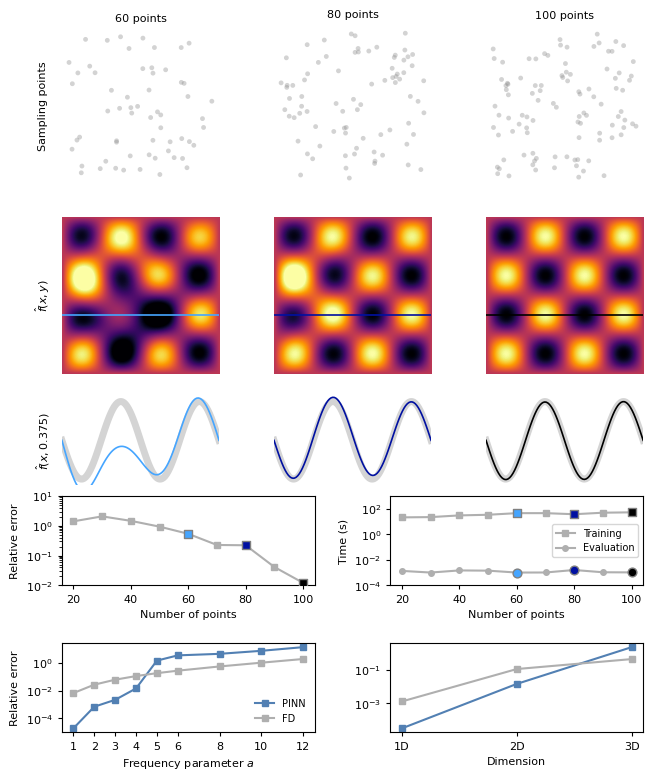

In [39]:
# Complete figure: base convergence study (rows 1-4) + frequency/dimension studies (row 5)
df_freq = pd.read_csv("data/pinn_freq_experiment.csv")
df_dim = pd.read_csv("data/pinn_dim_experiment.csv")
df_fd_freq = pd.read_csv("data/fd_freq_experiment.csv")
df_fd_dim = pd.read_csv("data/fd_dim_experiment.csv")

fig = plt.figure(figsize=(7.5, 9.3))
# Row 4 is an empty spacer so the x-labels of the error/time row stay visible
outer_gs = GridSpec(6, 1, height_ratios=[0.6, 0.6, 0.30, 0.30, 0.12, 0.30],
                    figure=fig, hspace=0.1)

colors = ['#45A5FF', "#0010A1", "#000000"]
N_examples = [60, 80, 100]
color_pinn = "#5280b3ff"
color_fd = "#AFAFAF"

def row_label(ax, text):
    ax.text(-0.12, 0.5, text, transform=ax.transAxes, fontsize=8,
            va="center", ha="center", rotation=90)

# Sampling points
gs_mesh = outer_gs[0].subgridspec(1, 3, wspace=0.35)
for i, N in enumerate(N_examples):
    ax = fig.add_subplot(gs_mesh[0, i])
    ax.scatter(np.random.rand(N), np.random.rand(N),
               marker='o', color="#919191", s=12.0, alpha=0.4, edgecolors='none')
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{N} points", fontsize=8, pad=6)
    if i == 0:
        row_label(ax, "Sampling points")

# Predicted fields (aligned with cross-sections)
gs_top = outer_gs[1].subgridspec(1, 3, wspace=0.35)
y_line = 0.375  # common cross-section line
for i, (N, color) in enumerate(zip(N_examples, colors)):
    ax = fig.add_subplot(gs_top[0, i])
    X, Y, F_pred, _ = results_dict[N]
    ax.imshow(F_pred.T, extent=(0, 1, 0, 1), cmap="inferno",
              vmin=-1, vmax=1, origin="lower", interpolation="bilinear")
    ax.axhline(y_line, color=color, lw=1.2)
    ax.set_aspect("equal")
    ax.axis("off")
    if i == 0:
        row_label(ax, r"$\hat{f}(x,y)$")

# 1D cross-section comparison (aligned with row 2)
gs_mid = outer_gs[2].subgridspec(1, 3, wspace=0.35)
for i, (N, color) in enumerate(zip(N_examples, colors)):
    ax = fig.add_subplot(gs_mid[0, i])
    X, Y, F_pred, F_true = results_dict[N]
    idx = np.argmin(np.abs(Y[:, 0] - y_line))
    ax.plot(X[idx, :], F_true[idx, :], '-', color="#D4D4D4", lw=5.0, label="Exact")
    ax.plot(X[idx, :], F_pred[idx, :], '-', color=color, lw=1.2, label="PINN")
    ax.set_xlim(0, 1)
    ax.set_ylim(-1.15, 1.15)
    ax.axis("off")
    if i == 0:
        row_label(ax, r"$\hat{f}(x,0.375)$")

# Error and computational times vs number of points
gs_bottom = outer_gs[3].subgridspec(1, 2, wspace=0.3)
ax_errN = fig.add_subplot(gs_bottom[0, 0])
ax_errT = fig.add_subplot(gs_bottom[0, 1])

ax_errN.plot(N_values, relative_errors, '-', color='#AFAFAF', marker='s', markersize=4)
for N, color in zip(N_examples, colors):
    idx = np.where(N_values == N)[0][0]
    ax_errN.scatter(N_values[idx], relative_errors[idx],
                    color=color, marker='s', s=40, edgecolor='gray', zorder=3)
ax_errN.set_xlabel("Number of points")
ax_errN.set_ylabel("Relative error")
ax_errN.set_yscale("log")
ax_errN.set_ylim(top=1e1, bottom=1e-2)

ax_errT.plot(N_values, train_times, '-', color="#AFAFAF", marker='s',
             markersize=4, label="Training")
ax_errT.plot(N_values, eval_times, '-', color="#AFAFAF", marker='o',
             markersize=4, label="Evaluation")
for N, color in zip(N_examples, colors):
    idx = np.where(N_values == N)[0][0]
    ax_errT.scatter(N_values[idx], train_times[idx],
                    color=color, marker='s', s=40, edgecolor='gray', zorder=3)
    ax_errT.scatter(N_values[idx], eval_times[idx],
                    color=color, marker='o', s=40, edgecolor='gray', zorder=3)
ax_errT.set_xlabel("Number of points")
ax_errT.set_ylabel("Time (s)")
ax_errT.set_yscale("log")
ax_errT.set_ylim(top=1e3, bottom=1e-4)
ax_errT.legend(fontsize=7)

# Relative error vs frequency (2D, N = 100) and vs dimension (a = 4, N = 100)
gs_extra = outer_gs[5].subgridspec(1, 2, wspace=0.3)
ax_freq = fig.add_subplot(gs_extra[0, 0])
ax_dim = fig.add_subplot(gs_extra[0, 1])

ax_freq.plot(df_freq["a"], df_freq["mean_rel_error"], '-', color=color_pinn,
             marker='s', markersize=4, label="PINN")
ax_freq.plot(df_fd_freq["a"], df_fd_freq["rel_error"], '-', color=color_fd,
             marker='s', markersize=4, label="FD")
ax_freq.set_xlabel(r"Frequency parameter $a$")
ax_freq.set_ylabel("Relative error")
ax_freq.set_yscale("log")
ax_freq.set_xticks(df_freq["a"])
ax_freq.legend(fontsize=7, frameon=False)

ax_dim.plot(df_dim["dim"], df_dim["mean_rel_error"], '-', color=color_pinn,
            marker='s', markersize=4, label="PINN")
ax_dim.plot(df_fd_dim["dim"], df_fd_dim["rel_error"], '-', color=color_fd,
            marker='s', markersize=4, label="FD")
ax_dim.set_xlabel("Dimension")
ax_dim.set_yscale("log")
ax_dim.set_xticks([1, 2, 3])
ax_dim.set_xticklabels(["1D", "2D", "3D"])

# Save and display figure
os.makedirs("figs", exist_ok=True)
plt.savefig("figs/pinn_helmholtz2D.svg", dpi=150, bbox_inches="tight")
plt.savefig("figs/pinn_helmholtz2D.pdf", dpi=150, bbox_inches="tight")
plt.show()
